# Núcleo numérico: convergencia, acoplamiento y convenciones
## Preguntas
¿Se mide error de discretización o sólo ruido Monte Carlo? ¿Un promedio por rangos coincide con ES de masa fraccionaria? Se ejecutan dos contrastes sobre los kernels existentes, sin presentar un baseline educativo como definición universal de riesgo.

Los datos son sintéticos. El núcleo usa biblioteca estándar; este notebook añade NumPy, Pandas y Matplotlib para auditarlo.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
SEED=20261018


## Convergencia fuerte de Euler con ruido acoplado
Para GBM $dS=\mu Sdt+\sigma SdW$, el terminal exacto es $S_T=S_0\exp((\mu-\sigma^2/2)T+\sigma W_T)$. La comparación fuerte debe usar el mismo W_T que Euler, no terminales independientes.

Se generan incrementos en una malla fina y se suman para obtener todas las mallas gruesas. El RMSE entre terminales debería decrecer aproximadamente con Δt^1/2; se estima pendiente como diagnóstico, sin imponer un assert que fuerce el resultado.

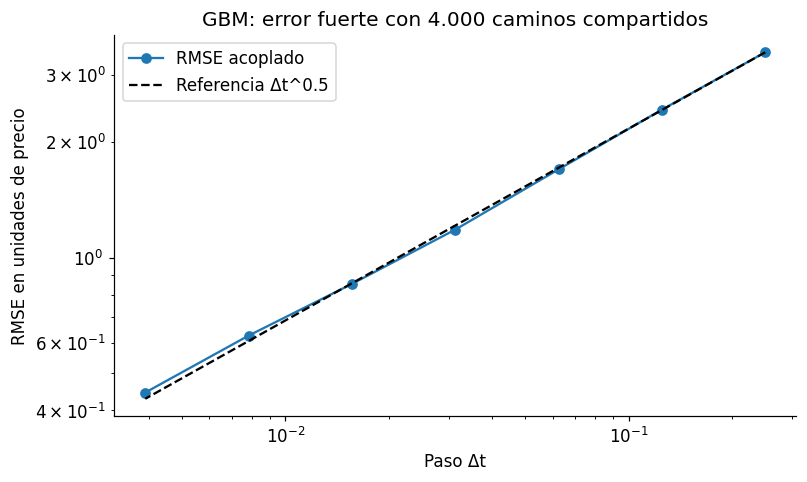

Orden fuerte medido: 0.49081713666750065


,steps,dt,strong_rmse,mean_bias,negative_fraction
0,4,0.250000,3.429336,-0.083580,0.0
1,8,0.125000,2.430652,-0.070865,0.0
2,16,0.062500,1.698300,-0.019490,0.0
3,32,0.031250,1.183050,-0.006489,0.0
4,64,0.015625,0.854111,-0.011956,0.0
5,128,0.007812,0.626224,-0.021864,0.0
6,256,0.003906,0.445006,-0.018562,0.0


In [2]:
from src.numerical_core import bs_call,mc_call,expected_shortfall
rng=np.random.default_rng(SEED);paths=4000;finest=256;T=1.;mu=.03;sigma=.3;s0=100.
dw=rng.normal(scale=np.sqrt(T/finest),size=(paths,finest))
exact=s0*np.exp((mu-.5*sigma**2)*T+sigma*dw.sum(axis=1))
convergence=[]
for steps in [4,8,16,32,64,128,256]:
    increments=dw.reshape(paths,steps,finest//steps).sum(axis=2)
    euler=s0*np.prod(1+mu*T/steps+sigma*increments,axis=1)
    convergence.append(dict(steps=steps,dt=T/steps,strong_rmse=np.sqrt(np.mean((euler-exact)**2)),
        mean_bias=(euler-exact).mean(),negative_fraction=np.mean(euler<0)))
convergence=pd.DataFrame(convergence);display(convergence.round(6))
order=np.polyfit(np.log(convergence.dt),np.log(convergence.strong_rmse),1)[0]
print('Orden fuerte medido:',order)
assert np.isfinite(convergence.strong_rmse).all()
fig,ax=plt.subplots(figsize=(8,4.5));ax.loglog(convergence.dt,convergence.strong_rmse,'o-',label='RMSE acoplado')
reference=convergence.strong_rmse.iloc[0]*np.sqrt(convergence.dt/convergence.dt.iloc[0])
ax.loglog(convergence.dt,reference,'--',color='black',label='Referencia Δt^0.5')
ax.set(xlabel='Paso Δt',ylabel='RMSE en unidades de precio',title='GBM: error fuerte con 4.000 caminos compartidos')
ax.legend();plt.show()

## Error Monte Carlo frente a Black–Scholes
Un estimador sin discretización aún tiene ruido Monte Carlo. La referencia analítica comprueba unidades, descuento y convención de payoff. Se promedian errores cuadrados entre 30 semillas por tamaño; no se espera que una sola realización mejore monótonamente.

In [3]:
oracle=bs_call(100,100,.03,.3,1)
mc_rows=[]
for count in [500,2000,8000]:
    errors=[];ses=[]
    for replicate in range(30):
        result=mc_call(100,100,.03,.3,1,paths=count,seed=SEED+replicate)
        errors.append(result['price']-oracle);ses.append(result['standard_error'])
    mc_rows.append(dict(paths=count,rmse=np.sqrt(np.mean(np.array(errors)**2)),reported_se=np.mean(ses)))
display(pd.DataFrame(mc_rows))
assert oracle>=max(100-100*np.exp(-.03),0)
print('Precio analítico:',oracle)

Precio analítico: 13.283308397880909


,paths,rmse,reported_se
0,500,1.163080,0.974803
1,2000,0.436680,0.489976
2,8000,0.252782,0.244400


## Convención de Expected Shortfall del baseline
El kernel histórico toma un promedio desde el índice VaR por rangos. Para 99 ceros y una pérdida de 100, α=0.975, integra tres observaciones completas: 100/3. ES de masa exactamente 0.025 integra 2.5 observaciones equivalentes y vale 40. Ambas cifras pueden ser reproducibles y representar definiciones distintas.

No se modifica el kernel histórico silenciosamente; la auditoría ES ponderada del dominio 03 implementa la integración de masa fraccionaria y debe usarse cuando ése sea el contrato requerido.

In [4]:
losses=[0.]*99+[100.]
legacy=expected_shortfall(losses,.975)
exact_fractional=100/(100*(1-.975))
display(pd.DataFrame({'convención':['Rangos completos del núcleo','Masa fraccionaria'],
    'valor':[legacy,exact_fractional]}))
assert np.isclose(legacy,100/3) and np.isclose(exact_fractional,40)
print('Diferencia definicional:',exact_fractional-legacy)

Diferencia definicional: 6.666666666666629


,convención,valor
0,Rangos completos del núcleo,33.333333
1,Masa fraccionaria,40.000000


## Conclusiones y alcance
El primer experimento separa error fuerte de discretización mediante acoplamiento. El segundo contrasta ruido de integración con una fórmula analítica. El tercero muestra que precisión numérica no resuelve ambigüedad de definición. Ninguno valida parámetros financieros observados ni cobertura de eventos extremos.